# Fast Reflexes on the Robot and a Slower World-Model Brain on Anyscale

### Serve a robot's **world model** in the cloud with Ray, and reconcile its *always-late* advice with the robot's real-time reflex

Today's robot policies (VLAs) are brilliant **reflexes**. They transform observations into actions in one shot. However, a reflex
can't *deliberate*. A **world model** is a learned model of *what happens next given an action*. It lets a
robot **imagine and search** for a good action. That search is heavy (billion-parameter rollouts over many
imagined futures), so it belongs in the cloud. LLMs crossed this same line with **test-time compute**
(the "think longer, answer better" behind o1-style reasoning). This is its control analogue.

But the moment you put the thinking in the cloud, you inherit a hard, unsolved problem. That being **the cloud's
answer is always stale.** It is computed for where the robot *was* when it asked, and it arrives seconds
later, after the fast reflex has already moved on. Naively applying stale advice is *worse* than ignoring it as it adds a correction meant for the old pose onto the new one, sending the robot to a spot neither it nor the cloud intended.

> The unlock is **reconciliation**, where you may choose to fuse the live reflex with the delayed cloud correction so the robot
> ends up where the cloud's smarter plan intended, *starting from where it actually is now*.

Note that **reconciliation is an open research problem.** If we define the original snapshot pose as `p0` (where the robot was when it asked), and the cloud's advised move as `a_cloud`. The vector-addition rule we use here, where we treat the cloud's answer as an intended destination (i.e. `p0` + `a_cloud`) and steer toward it, is the simplest instance, and the one we demonstrate. But *how* you should fuse a stale plan with a live reflex is deeply context-dependent, and the logic can be complex. In a fast, dynamic setting the robot may need to **ignore** the cloud's target and trust its fast policy instead. Say, if something dangerous has appeared right where the cloud pointed (falling debris, a person stepping in, an object that moved since the snapshot, etc). Richer reconcilers might blend the two by staleness, hand control to the reflex when a correction is too old or unsafe, or *learn* the fusion per embodiment. We show the clean vector-add case to make the idea concrete and treat it as the first example.

**This is a Ray + Anyscale workload end to end**. The slow brain is a **Ray Serve** service, and
scaling it (more GPUs → faster plans → *less staleness to reconcile*) is a config change and not a rewrite.

| What serving this needs | Assemble it yourself | On Ray + Anyscale |
|---|---|---|
| Serve a multi-GB GPU model over HTTP | FastAPI + a process manager, load the model per worker, wire up health checks and GPU pinning | `@serve.deployment(num_gpus=1)` — model loaded once per replica, HTTP ingress included *(shown here)* |
| Make one plan faster (shard the search across GPUs) | Custom multiprocessing / NCCL, your own RPC and result-gather | `ShardWorker` actors + fan-out/reduce — near-linear, **18.4 s → 4.3 s on 4 L4s** *(shown here)* |
| Serve a fleet of robots | A Deployment + external load balancer + readiness probes | `.options(num_replicas=N)` — the Serve proxy load-balances |
| Scale to demand | Cluster-autoscaler + HPA + custom GPU metrics, tuned by hand | Replica **and** node autoscaling, built in |
| Get 11 GB of weights + your code onto every GPU | Bake into images and rebuild on every change and run a registry | Shared cluster storage + `runtime_env` ships code and deps — no image rebuild |
| Go from laptop → dev cluster → prod | Different stacks locally vs. in prod + dealing with config drift | The *same* `serve.run` everywhere — the dev cluster mirrors prod |

*The first two rows run live in this notebook. The rest are the production path the same code grows into.*

## This is Mission Control's problem, generalized

A spacecraft (the fast brain) flies itself second-by-second. It never freezes waiting for Earth. Mission
Control (the slow cloud) works out a maneuver from telemetry that's already minutes old, so the command
arrives *stale* as it was computed for where the craft *was*, not where it is. That's exactly why the ground may choose to send
a **destination**. This is the target state to reach rather than raw stick-and-throttle commands. The craft
closes the gap to that intended state from wherever it actually is at present time.

Autonomous-driving stacks already run this split with heavy compute off-vehicle and a tightly-budgeted policy
on the car. We generalize it with a **learned world model** the robot can search inside, so it works for
general-purpose robots where you can't hand-author a simulator. Our substrate is Meta's open,
action-conditioned **V-JEPA 2-AC** (MIT). Planning is done via the **Cross-Entropy Method** (sample actions, roll
them forward *in latent space*, keep the ones whose imagined outcome lands closest to the goal).

**One idea to hold onto** is that V-JEPA doesn't predict pixels. Rather, it compresses each observation into a compact
*latent* and predicts how that latent changes when the robot acts. All the searching happens in that
latent space. The robot's 7-D end-effector **pose** is what we reconcile in.

## How the cloud "searches": the Cross-Entropy Method (CEM)

The cloud brain has no policy that spits out an action. Rather, it **searches** for one, and CEM is that search. It's a simple, gradient-free loop:

1. **Sample** a batch of candidate action sequences from a Gaussian (start broad).
2. **Imagine** each one by rolling it forward through the V-JEPA world model. Here there is no robot nor pixels, but just latents.
3. **Score** each by how close its imagined outcome lands to the goal latent.
4. **Refit** the Gaussian to the best few ("elites") and repeat a handful of times.

The distribution collapses onto good actions, and its mean is the plan. There are two things to hold onto. (1) CEM needs **no gradients** (it just rolls the world model forward as a black box), and (2) it is **test-time compute**. More samples and more rounds buy a better plan (the o1 analogy, and later the reason we shard it across GPUs to keep it fast).

## The architecture

![architecture](images/architecture.png)

The fast reflex acts on the robot in milliseconds and steers toward a destination. The slow world-model
brain is **served on Anyscale with Ray Serve** and thinks in seconds. The **reconciler** fuses the cloud's
always-late corrected destination into the robot's live motion. Everything below builds and runs exactly
this loop, end-to-end, on the cluster.

## 1. Connect to the cluster

We ship our modules to every node with `py_modules` and point the world-model weight cache at shared
cluster storage so each GPU loads the 11 GB checkpoint locally.

The demo is **four small modules**, shipped to every node below and opened up as we use them:

- **`vjepa_core.py`**: the world-model core: encode a frame → latent, roll latents forward given an action (the dynamics), CEM-plan an action chunk, score energy to a goal.
- **`slow_brain_service.py`**: wraps that core as the Ray Serve deployment (the cloud brain).
- **`world.py`**: a Ray actor holding the robot's *true* state (our stand-in for physical reality).
- **`robot_client.py`**: the on-robot fast brain + reconciler (plain numpy, no GPU). The fast brain is the distilled reflex. More specifically, it's a one-shot MLP that maps the perceived latent to a bounded action every tick (reactive, no search). The reconciler anchors the cloud's stale correction at the retained snapshot pose.

Each section below quotes the key code from the file it uses, so nothing important is hidden behind an import.

In [1]:
import os, sys, time, pickle, warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("ray.serve").setLevel(logging.ERROR)  # keep the notebook output to the narrative
import numpy as np
import requests
import matplotlib.pyplot as plt
import ray
from ray import serve
from IPython.display import Image

REPO = "/home/ray/default/robotics_world_model_inference/v2_reconciliation"
TORCH_HOME = "/mnt/cluster_storage/torch_hub"
VJEPA_REPO = f"{TORCH_HOME}/hub/facebookresearch_vjepa2_main"
sys.path.insert(0, REPO)

# log_to_driver=False keeps the notebook clean: the slow brain's per-CEM-step and Ray Serve logs stay on
# the worker nodes; we only surface the robot client's own progress lines here.
ray.init(address="auto", logging_level="ERROR", log_to_driver=False, runtime_env={
    "py_modules": [f"{REPO}/vjepa_core.py", f"{REPO}/slow_brain_service.py",
                   f"{REPO}/world.py", f"{REPO}/robot_client.py",
                   f"{REPO}/sharded_planner.py", f"{REPO}/reflex_policy.py"],
    "env_vars": {"TORCH_HOME": TORCH_HOME, "HF_HOME": "/mnt/cluster_storage/hf_cache",
                 "PYTORCH_CUDA_ALLOC_CONF": "expandable_segments:True"},
})
print("cluster GPUs available:", int(ray.cluster_resources().get("GPU", 0)))

cluster GPUs available: 4


## 2. Serve the slow brain on Ray Serve

**Ray Serve** is an open-source library for serving models as scalable online inference APIs ([docs](https://docs.ray.io/en/latest/serve/index.html)). You take an ordinary Python class, add the **`@serve.deployment`** decorator, and Ray turns it into an HTTP service running on the cluster where it starts one or more GPU worker processes (**replicas**), loads your model into each, puts a web server out front (**ingress**), and routes and load-balances requests across the replicas. That's the jump from "a model that runs in a script" to "a model served in production", and on Anyscale those replicas run on managed, autoscaling infrastructure. (See the Serve [key concepts](https://docs.ray.io/en/latest/serve/key-concepts.html) for deployments, replicas, and ingress.)

Here, that class *is* our world model, but there's a catch. A **usable** plan needs a real search (128 samples × 6 CEM steps × 2-step rollouts), which is **~18 s on a single GPU**. That's far too slow to serve for our purposes. So we serve it **data-parallel**, where one plan's search is sharded across a pool of GPU workers (`build_sharded_app(n_shards=3, ...)`), a coordinator takes the global best, and the plan comes back in **~6 s**. This is the heart of the Anyscale story that *the cloud has to be big to be useful, so we scale it across GPUs to make it servable at all* (more in §7). A robot POSTs a snapshot — its latent + pose + the goal latent — and the service returns an action chunk toward the goal. Serving a whole fleet later is another config knob: **`.options(num_replicas=N)`**.

### Under the hood: `slow_brain_service.py` + `sharded_planner.py`

The served slow brain is **data-parallel**: a coordinator (no GPU) that shards one CEM plan across a pool of GPU workers (from **`slow_brain_service.py`**):

```python
# slow_brain_service.py
@serve.deployment(ray_actor_options={"num_gpus": 0}, max_ongoing_requests=8)  # coordinator holds no GPU
@serve.ingress(app)
class ShardedSlowBrain:
    def __init__(self, n_shards=3, total_samples=128, cem_steps=6, rollout=2):
        self.workers = [ShardWorker.remote() for _ in range(n_shards)]   # each ShardWorker = 1 GPU + model

    @app.post("/plan")
    async def plan_http(self, request: Request):
        req = pickle.loads(await request.body())            # {z, pose, z_goal}
        action = plan_sharded(self.workers, req["z"], req["pose"], req["z_goal"],
                              self.total_samples, self.cem_steps, self.rollout)   # fan out + reduce
        chunk = action[0]                                   # [rollout, 7]
        return Response(content=pickle.dumps({"chunk": chunk}), media_type="application/octet-stream")
```

The coordinator itself holds no GPU. Each `ShardWorker` holds one GPU + a copy of the model. `plan_sharded` (see §7) splits the 128-sample search across the workers and reduces, so the usable plan that takes ~18 s on one GPU comes back in ~6 s across 3. The CEM itself lives in **`vjepa_core.py`** (`cem_plan`): sample action chunks, roll each `rollout` steps through the V-JEPA predictor, keep the `top-k` whose imagined latent lands closest to the goal, refit, repeat. `samples × rollout × cem_steps` rollouts of a billion-parameter model, which is the seconds of GPU work we're serving.

In [2]:
from slow_brain_service import build_sharded_app

# The *usable* cloud (128x6x2 CEM) is heavy — ~18 s on a single GPU, too slow to serve live. So we serve
# it DATA-PARALLEL: shard one plan's search across 3 GPU workers (leaving 1 GPU for the World oracle).
serve.run(build_sharded_app(n_shards=3, total_samples=128, cem_steps=6, rollout=2),
          name="slow_brain", route_prefix="/")
URL = "http://127.0.0.1:8000"
print("slow brain health:", requests.get(URL + "/health", timeout=180).json())

INFO 2026-07-01 19:39:34,850 serve 199822 -- Started Serve in namespace "serve".


INFO 2026-07-01 19:40:07,928 serve 199822 -- Application 'slow_brain' is ready at http://0.0.0.0:8000/.


slow brain health: {'ok': True, 'calls': 0, 'shards': 3}


## 3. The task, and the robot's "world"

We use a short Franka manipulation clip shipped with V-JEPA 2. More specifically, a **context** frame (where the arm is) and
a **goal** frame. The `World` actor is our stand-in for physical reality. It holds the *true* latent + pose **and the world-model predictor that advances them** as the robot acts. The robot can read its current pose and execute actions each tick (i.e. its sensors and motors) but it doesn't carry the billion-parameter world model, so it can't imagine futures on its own. That's exactly why it snapshots its state to the cloud, which *does* hold the model, and plans there. We build the goal a few steps away so there's room to move.

### Under the hood: `world.py` (dynamics from `vjepa_core.py`)

The `World` actor holds the **true** `(latent, pose)` and the predictor that advances them. The robot reads its pose and acts through `step()`/`snapshot()` each tick, but never runs this model itself as that's the cloud's job (from **`world.py`**):

```python
# world.py
@ray.remote(num_gpus=1)
class World:
    def build_problem(self, ctx_img, goal_img, pose_np, goal_steps=8, a_star=None):
        z0   = self.core.encode(ctx_img)                     # frame -> latent
        pose = self.core.t(pose_np).reshape(1, 1, 7)
        a    = self.core.t(a_star or [0.04,0,0,0,0,0,0]).reshape(1, 1, 7)
        z, p = z0, pose
        for _ in range(goal_steps):                          # synthesize a REACHABLE goal:
            z, p = self.core.step(z, p, a)                   #   roll a fixed action goal_steps forward
        self.z, self.pose, self.z_goal, self.p_goal = z0, pose, z, p

    def step(self, action_np, drift_np=None):                # advance the TRUE state
        a = self.core.t(action_np).reshape(1, 1, 7)
        if drift_np is not None:
            a = a + self.core.t(drift_np).reshape(1, 1, 7)   # unmodeled disturbance the planner never sees
        self.z, self.pose = self.core.step(self.z, self.pose, a)
        return {"pose": ..., "pose_err": ...,
                "z_pool": self.z[:, -1].mean(1).flatten()}   # pooled latent = the reflex's perception

    def snapshot(self):                                      # what the robot ships to the cloud
        return {"z": ..., "pose": ...}
```

The goal is built by rolling the predictor forward, so it's guaranteed reachable. `step` can add `drift`, which is a push the cloud plan never accounts for. This is what makes staleness *hurt*. `step` also returns `z_pool`, which is a pooled latent summary, exactly the perception the on-robot distilled reflex acts on each tick. The dynamics itself is one call into **`vjepa_core.py`**:

```python
# vjepa_core.py: one dynamics step, entirely in latent space (no pixels decoded)
def step(self, z, pose, action):
    nxt = self.predictor(...)                    # predict the NEXT latent given the action
    return nxt, compute_new_pose(pose, action)   # and advance the interpretable 7-D pose
```

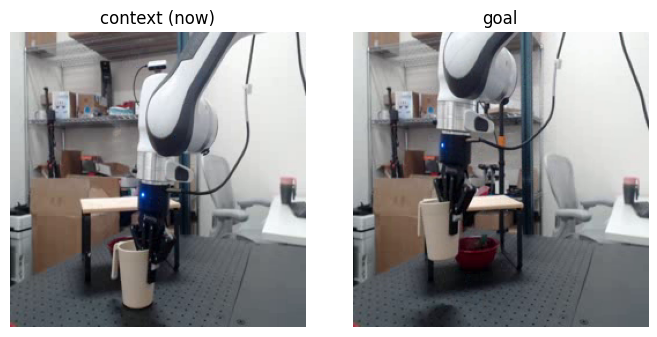

In [3]:
from world import World

world = World.remote()
traj = np.load(f"{VJEPA_REPO}/notebooks/franka_example_traj.npz")
ctx_img, goal_img = traj["observations"][0, 0], traj["observations"][0, 1]
prob = ray.get(world.build_problem.remote(ctx_img, goal_img, traj["states"][0, 0], goal_steps=8))
z_goal = prob["z_goal"]

fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
ax[0].imshow(ctx_img); ax[0].set_title("context (now)"); ax[0].axis("off")
ax[1].imshow(goal_img); ax[1].set_title("goal"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 4. One real cloud plan and why it can't run on the robot

We POST one real snapshot to the served slow brain and time the round-trip. The world model *thinks* for
seconds while a robot control loop is **10–50 ms**. That gap is the whole problem. The answer is many control
ticks stale by the time it lands. (This is the **sharded** cloud from §2 that's ~6 s across 3 GPUs. A single GPU would be ~18 s.)

The `requests.post` below hits the `/plan` route defined in **`slow_brain_service.py`** (shown above). The payload is a pickled `{z, pose, z_goal}` and the reply is `{chunk, compute_ms, seq_id}`.

In [4]:
ray.get(world.reset.remote(prob["z0"], prob["p0"]))
snap = ray.get(world.snapshot.remote())
req = {"z": snap["z"], "pose": snap["pose"], "z_goal": z_goal, "seq_id": 0}

t0 = time.time()
r = requests.post(URL + "/plan", data=pickle.dumps(req),
                  headers={"Content-Type": "application/octet-stream"}, timeout=300)
rtt = (time.time() - t0) * 1000
out = pickle.loads(r.content)
print(f"cloud plan: action chunk {out['chunk'].shape} | server compute {out['compute_ms']:.0f} ms | "
      f"round-trip {rtt:.0f} ms")
CONTROL_HZ = 2.0                        # the demo's control rate — the SAME loop the reconciliation episode below runs
print(f"at the demo's {CONTROL_HZ:.0f} Hz control loop that's ~{rtt/1000*CONTROL_HZ:.0f} control ticks STALE "
      f"by the time it lands — the same Δ the reconciliation episode below reconciles.")

cloud plan: action chunk (2, 7) | server compute 6162 ms | round-trip 6202 ms
at the demo's 2 Hz control loop that's ~12 control ticks STALE by the time it lands — the same Δ the reconciliation episode below reconciles.


## 5. Reconciliation: steer to the corrected destination

The cloud's action `a_cloud` was right *for the snapshot pose* `p0`. By the time it lands, the robot has
drifted to `p_now`. Two ways to use it:

- **Naive**: apply `a_cloud` from `p_now`. It was computed from a *different* starting point, so the
  robot carries the drift. Error grows with latency.
- **Vector-add reconciliation**: the cloud implied a **destination** `p0 + a_cloud` ("where I should have
  ended up"). Steer from `p_now` toward that destination: `correction = (p0 + a_cloud) − p_now`. The drift
  cancels. This requires the robot to *retain* `p0` until the matching reply arrives.

The robot's fast brain here is the **distilled reflex** from the intro. This is a one-shot learned policy that acts every control tick. On its own it's reactive. It heads toward the goal but, with no ability to plan ahead, it **drifts off and can't hold** (you'll see it climb in the plot below). The cloud's reconciled correction is what pulls it back.

That's it, and its pure vector arithmetic. Below, the robot runs its fast loop against the
**real** served slow brain. It snapshots, keeps acting while the cloud thinks, and reconciles each reply.
The staleness Δ here is *measured* from the real round-trip.

**Reading the plot below.** The y-axis is **distance to the goal** (0 = reached; this run starts ~0.32). We run the *same* robot twice from the same start: **gray** = reflex only (never gets the cloud), **blue** = reflex + reconciled cloud. Because the reflex is deterministic, the two are **identical until the first reply lands** — up to there, both are just the reflex drifting away from the goal. Then the stale cloud plan arrives (dashed line): the gray reflex keeps drifting (ends near 0.6), while the blue reconciled robot steers to the corrected destination and heads back toward the goal.

### Under the hood: `robot_client.py` — the fast brain, and where reconciliation happens

Two pieces run on the robot, both plain numpy (no GPU). The **distilled reflex** acts every tick, and once a cloud reply lands, the robot steers to the **reconciled destination** instead (from **`robot_client.py`**):

```python
# robot_client.py
def _reflex_action(reflex, z_pool_now, z_pool_goal):     # FAST BRAIN: one-shot distilled policy
    a = reflex.action_from_pooled(z_pool_now, z_pool_goal)   # tiny MLP on the perceived latent, no search
    a[:3] = np.clip(a[:3], -MAXNORM, MAXNORM); a[6] = np.clip(a[6], -MAXNORM, MAXNORM)
    return a.reshape(1, 1, 7)

def _destination(anchor_pose, chunk):                    # cloud's corrected destination = anchor + Sum(chunk)
    dest = anchor_pose.copy().reshape(7)
    dest[:3] += chunk[:, :3].sum(axis=0)
    return dest

# ... inside run_episode(), each control tick:
if destination is not None:                              # a cloud reply has landed -> steer to it
    action = _step_toward(pose, destination)
else:                                                    # still waiting -> the reflex acts (and drifts)
    action = _reflex_action(reflex, z_pool_now, z_pool_goal)

# reconciliation, the moment a reply arrives:
anchor = pose if strategy == "naive" else pc["snap_pose"]   # <-- THE ENTIRE DIFFERENCE
destination = _destination(anchor, chunk)
```

The reflex is a real learned policy but reactive, so it drifts. **`naive`** anchors the cloud's move at the *current, drifted* pose (carries the drift). **`vector_add`** anchors at `snap_pose` — the pose `p0` retained from the snapshot, so the destination is exactly where the cloud intended and the drift cancels.

    [vector_add] tick 12: cloud reply (req@0) Δ=12 ticks, latency=5754ms, pose_err=0.406



measured staleness Δ ≈ 12 control ticks (from 5754 ms real cloud latency)


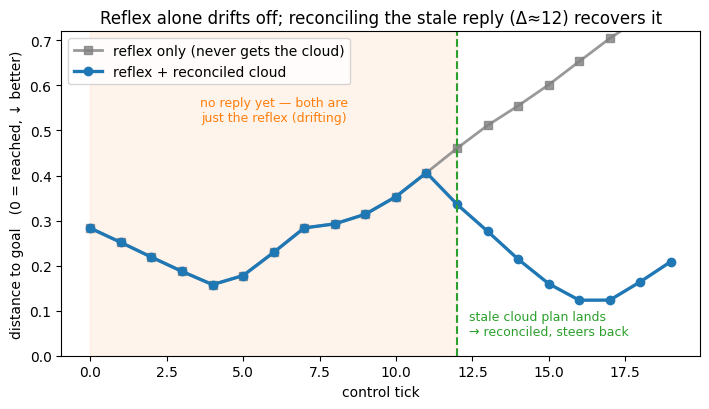

In [5]:
from robot_client import run_episode
from reflex_policy import ReflexPolicy

reflex = ReflexPolicy(f"{REPO}/reflex_policy.npz")   # the distilled fast brain (one-shot, numpy, no GPU)
DRIFT = [0.0, 0.02, 0.0, 0.0, 0.0, 0.0, 0.0]         # a small unmodeled disturbance (miscalibration/push)

# Same robot, same start, same disturbance, run twice: reflex ALONE, then reflex + the cloud.
# The reflex is deterministic, so the two runs are identical until the first cloud reply lands.
ray.get(world.reset.remote(prob["z0"], prob["p0"]))
res_reflex = run_episode(world, URL, z_goal, strategy="reflex", reflex=reflex,
                         control_hz=2.0, horizon=20, drift=DRIFT)
ray.get(world.reset.remote(prob["z0"], prob["p0"]))
res = run_episode(world, URL, z_goal, strategy="vector_add", reflex=reflex,
                  control_hz=2.0, horizon=20, drift=DRIFT)

print(f"\nmeasured staleness Δ ≈ {res['mean_delta']:.0f} control ticks "
      f"(from {res['mean_latency_ms']:.0f} ms real cloud latency)")
first_reply = res["reply_ticks"][0] if res["reply_ticks"] else int(res["mean_delta"])
plt.figure(figsize=(7.2, 4.2))
plt.plot(res_reflex["pose_err"], "s-", color="gray", lw=2, alpha=0.8, label="reflex only (never gets the cloud)")
plt.plot(res["pose_err"], "o-", color="C0", lw=2.4, label="reflex + reconciled cloud")
plt.axvspan(0, first_reply, color="C1", alpha=0.08)                       # no reply yet: both are the reflex
plt.axvline(first_reply, color="C2", ls="--", lw=1.5)                     # the stale cloud reply lands
plt.text(first_reply / 2, 0.52, "no reply yet — both are\njust the reflex (drifting)", ha="center",
         color="C1", fontsize=9)
plt.text(min(first_reply + 0.4, len(res["pose_err"]) - 1), 0.04,
         "stale cloud plan lands\n→ reconciled, steers back", color="C2", fontsize=9, va="bottom")
plt.ylim(0, 0.72)
plt.xlabel("control tick"); plt.ylabel("distance to goal   (0 = reached, ↓ better)")
plt.title(f"Reflex alone drifts off; reconciling the stale reply (Δ≈{res['mean_delta']:.0f}) recovers it")
plt.legend(loc="upper left"); plt.tight_layout(); plt.show()

## 6. The payoff: reconciliation vs. naive, as the cloud goes stale

A single live run is noisy (only a couple of corrections land). The chart below is the controlled, seed-averaged sweep on this 4×L4 cluster (reproducible via `old/p1_run.py`), using **pose error to the goal**. This is an exact metric.

Three strategies as staleness Δ grows: (1) **reflex-only** ignores the cloud and stays stuck near 0.6 (it drifts and can't hold). (2) **naive** applies the stale plan as-is and climbs back up toward that reflex baseline as the advice ages. (3) **vector-add reconciled** stays low. That's the thesis. reconciliation is what lets you use a late-but-smarter cloud without it hurting you.

These are **illustrative demo numbers**. The search is stochastic and deliberately under-resourced on 4 small GPUs (hence the spread, and the overlap at tiny Δ where there is little staleness to reconcile). A production cloud is bigger, tuned, and tighter; the *shape* is the point, not the decimals.

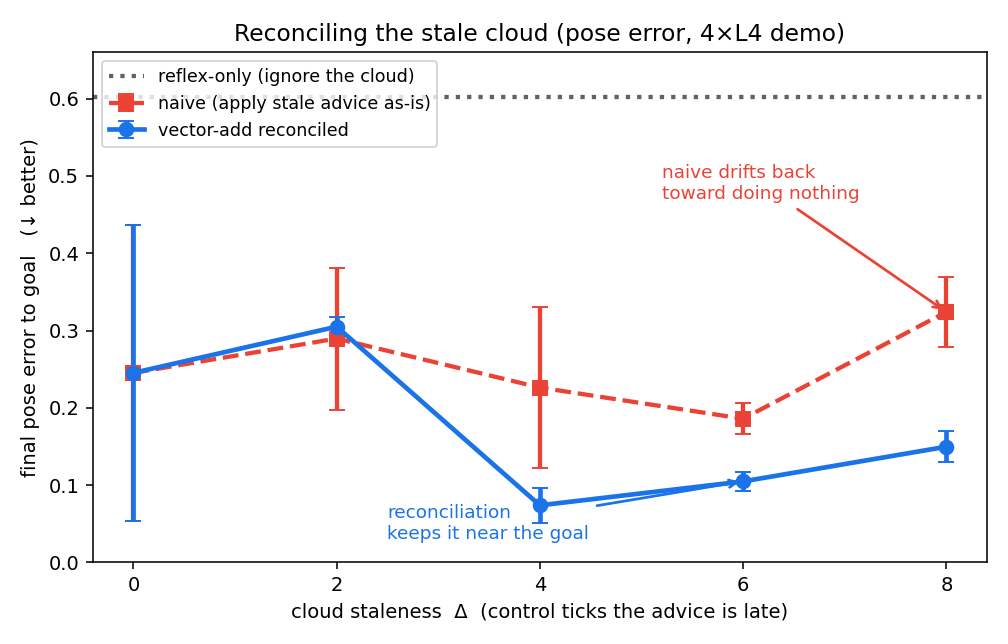

In [6]:
Image(filename=f"{REPO}/images/p1_feasibility.png")

## 7. Scale the slow brain on Anyscale — this is what made it servable

Recall §2: the *usable* cloud is ~18 s/plan on one GPU. We didn't just note that — we **served it data-parallel**, sharding one CEM plan's sample batch across 3 GPUs so the plan comes back in ~6 s. That is the same lever, and it is the heart of the Anyscale story: **more GPUs → a faster plan → less staleness to reconcile → a real-time-usable cloud.** Each GPU rolls part of the search; a coordinator takes the global best and refits.

Below, plan latency vs. GPU count (reproducible via `old/p2_shard_test.py`): near-linear, an **18.4 s plan → 4.3 s across 4 GPUs**. On production accelerators (H100/H200/B200) the *same* code drops it toward sub-second — the curves shift down and to the left; the fast brain still runs in ms on the robot regardless.

### Under the hood: `sharded_planner.py` — data-parallel CEM

This is the code behind the **served** cloud (§2) and the scaling chart below — splitting **one** CEM plan's sample batch across GPUs (from **`sharded_planner.py`**):

```python
# sharded_planner.py
def plan_sharded(workers, z, pose, zg, total_samples=128, cem_steps=6, rollout=2):
    per = total_samples // len(workers)                       # split the batch across G GPUs
    for step in range(cem_steps):
        shards  = ray.get([w.roll_and_score.remote(mean, std, per, rollout, ...)  # each GPU rolls
                           for w in workers])                                      # its own share
        actions = np.concatenate([a for a, _ in shards])      # ...returning only tiny
        scores  = np.concatenate([s for _, s in shards])      #    (action, score) arrays
        idx     = np.argsort(scores)[:topk]                   # GLOBAL top-k across all shards
        top     = actions[idx]                                # the winners
        mean = top.mean(0)*(1-m) + mean*m                     # momentum-refit the sampling
        std  = top.std(0)*(1-m)  + std*m                      #   distribution, then repeat
    ...
```

Each `ShardWorker` rolls its candidates through its own copy of the predictor (the expensive part) and returns only small `(action, score)` arrays; the coordinator takes the global top-k and refits. Latents stay on-GPU — only tiny vectors cross the wire — which is why the speedup is near-linear.

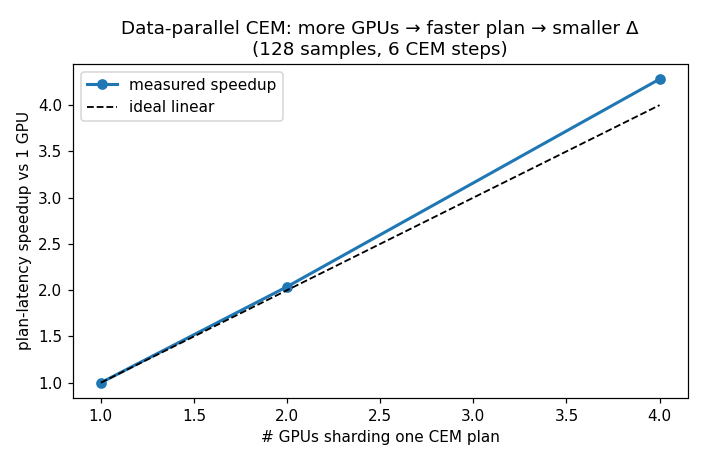

In [7]:
Image(filename=f"{REPO}/images/p2_shard_scaling.png")

## 8. Δ is a dial — the production consideration

Staleness isn't a fixed number; it's the ratio of cloud latency to the robot's control period, and it's a
**design dial**:

- **Slow the robot** (deliberate tasks — careful insertion, easing through a doorway) → Δ shrinks to a few
  ticks. But you can't slow a *balancing* or *fast-contact* task without it falling over — those need
  100–1000 Hz, which pushes Δ into the hundreds.
- **Speed up the cloud** (more GPUs via the shard lever above, faster accelerators, fp8 / `torch.compile`
  / FlashAttention) → Δ shrinks with no change to the robot.

The one thing you *can't* do is make Δ zero: the cloud is always slower than the reflex (that's why it's a
separate brain), so some staleness always remains — and reconciliation is what makes running the two
brains at different speeds safe. Crank the robot faster and Δ grows, so reconciliation matters *more*, not
less. **Planning is elastic cloud compute; the reflex is a cheap edge policy; reconciliation is the glue.**

## 9. The standing architecture

Run this continuously: the fast reflex acts on the robot in milliseconds; the **slow brain thinks in the
cloud on Anyscale**, served with Ray and scaled by a number; and a reconciliation layer fuses the cloud's
always-late, always-smarter corrections into the robot's live motion. Fast brain on the robot, slow brain
on Anyscale — with the hard part, *reconciling the two*, done honestly.

In [8]:
ray.kill(world)
serve.shutdown()
print("slow brain + world released.")

(raylet) Task ServeController.graceful_shutdown failed. There are infinite retries remaining, so the task will be retried. Error: The actor is dead because it was killed by `ray.kill`.


slow brain + world released.
